In [11]:
%matplotlib inline
import matplotlib.pyplot as plt

# Увеличит качество экспортируемых рисунков
plt.rcParams['figure.dpi'] = 150

In [12]:
from pathlib import Path

BASE_DIR = Path(".")  # или Path(__file__).resolve().parent в .py-скрипте
DATA_DIR = BASE_DIR / "data"
CACHE_PATH = BASE_DIR / "cache" / "spores_index_final.npz"
OUTPUT_DOCX = BASE_DIR / "reports" / "spore_report.docx"

In [3]:
from pathlib import Path
from typing import Union, List, Optional
import numpy as np
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
from torchvision import models, transforms


class EfficientNetFeatureExtractor:
    def __init__(
        self,
        device: Optional[str] = None,
        n_components: Union[int, float] = 0.95,
        random_state: int = 42
    ):
        """
        :param device: 'cuda', 'cpu' или None (автоматический выбор)
        :param n_components: Количество компонент PCA (int) или доля объясненной дисперсии (float, например 0.95)
        :param random_state: Сид для воспроизводимости PCA
        """
        if device is None:
            self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        else:
            self.device = torch.device(device)

        print(f"[INFO] Инициализация экстрактора на устройстве: {self.device}")

        # 1. Загрузка предобученной EfficientNetB2
        weights = models.EfficientNet_B2_Weights.DEFAULT
        self.model = models.efficientnet_b2(weights=weights)

        # Отбрасываем классификатор (оставляем backbone + pooling -> 1408 фич)
        self.model.classifier = nn.Identity()
        self.model.to(self.device)
        self.model.eval()

        # 2. Трансформации
        self.transform = transforms.Compose([
            transforms.Resize((260, 260), interpolation=transforms.InterpolationMode.BICUBIC), #288x288
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

        # 3. PCA и StandardScaler
        self.scaler = StandardScaler()
        self.pca = PCA(n_components=n_components, random_state=random_state)
        self.is_pca_fitted = False

    def extract_raw(self, pil_image: Image.Image) -> np.ndarray:
        """
        Извлекает исходный 1408-мерный вектор (без PCA и без L2-нормализации).
        """
        if pil_image.mode != 'RGB':
            pil_image = pil_image.convert('RGB')

        tensor = self.transform(pil_image).unsqueeze(0).to(self.device)

        with torch.no_grad():
            features = self.model(tensor)
            feature_vector = features.cpu().numpy().flatten()

        return feature_vector

    def fit_pca(self, raw_features: np.ndarray) -> None:
        """
        Обучает StandardScaler и PCA на матрице сырых фич формата (N_samples, 1408).
        """
        if raw_features.ndim != 2 or raw_features.shape[1] != 1408:
            raise ValueError(f"Ожидался массив формы (N, 1408), получено: {raw_features.shape}")

        print(f"[INFO] Обучение PCA на выборке из {raw_features.shape[0]} объектов...")

        # Стандартизация (среднее = 0, std = 1)
        scaled_features = self.scaler.fit_transform(raw_features)

        # Обучение PCA
        self.pca.fit(scaled_features)
        self.is_pca_fitted = True

        print(f"[INFO] PCA обучен: 1408 -> {self.pca.n_components_} компонент "
              f"(сохранено {sum(self.pca.explained_variance_ratio_):.2%} дисперсии)")

    def extract(self, pil_image: Image.Image, use_pca: bool = True) -> np.ndarray:
        """
        Извлекает вектор, применяет PCA (если обучен и выключен) и выполняет L2-нормализацию.
        """
        vector = self.extract_raw(pil_image)

        # Применение PCA (если доступен и запрошен)
        if use_pca:
            if not self.is_pca_fitted:
                raise RuntimeError("PCA не обучен! Сначала вызовите method .fit_pca(raw_features_matrix) "
                                   "или передайте use_pca=False.")

            # Масштабирование и трансформация через PCA
            vector_scaled = self.scaler.transform(vector.reshape(1, -1))
            vector = self.pca.transform(vector_scaled).flatten()

        # L2-нормализация выполняется строго ПОСЛЕ PCA
        norm = np.linalg.norm(vector)
        if norm > 0:
            vector = vector / norm

        return vector

In [4]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# ==========================================
# 1. ФУНКЦИЯ ПОСТРОЕНИЯ / ЗАГРУЗКИ ИНДЕКСА
# ==========================================

def build_or_load_index(processed_db_folder: str | Path = DATA_DIR, index_cache_path: str | Path = CACHE_PATH, extractor = None):
    cache_file = Path(index_cache_path)

    if extractor is None:
        extractor = EfficientNetFeatureExtractor()

    # --- ЗАГРУЗКА ИЗ КЭША ---
    if cache_file.exists():
        print(f"[INFO] Загрузка готового индекса и PCA из кэша: {index_cache_path}")
        try:
            data = np.load(index_cache_path, allow_pickle=True)

            # Восстанавливаем состояние PCA и Scaler
            if 'pca_mean' in data and 'pca_components' in data:
                extractor.scaler.mean_ = data['pca_mean']
                extractor.scaler.scale_ = data['pca_scale']
                extractor.pca.components_ = data['pca_components']
                extractor.pca.explained_variance_ = data['pca_explained_variance']
                extractor.pca.explained_variance_ratio_ = data['pca_explained_variance_ratio_']
                extractor.pca.mean_ = data['pca_pca_mean']
                extractor.pca.n_components_ = len(data['pca_components'])
                extractor.is_pca_fitted = True
                print(f"[INFO] Состояние PCA успешно восстановлено из кэша ({extractor.pca.n_components_} компонент).")

            return data['vectors'], data['labels'], data['paths']
        except Exception as e:
            print(f"[WARNING] Ошибка загрузки кэша ({e}). Построение индекса заново...")

    # --- ПОСТРОЕНИЕ ИНДЕКСА ЗАНОВО ---
    print(f"[INFO] Индексация предобработанных изображений из '{processed_db_folder}'...")

    db_path = Path(processed_db_folder)
    valid_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

    raw_vectors, labels, paths = [], [], []

    for file_path in db_path.rglob('*'):
        if file_path.suffix.lower() in valid_extensions:
            try:
                rel_path = file_path.relative_to(db_path)
                genus_label = rel_path.parts[0]

                img_pil = Image.open(file_path)
                raw_vec = extractor.extract_raw(img_pil)

                raw_vectors.append(raw_vec)
                labels.append(genus_label)
                paths.append(str(file_path))
            except Exception as e:
                print(f"[ERROR] Ошибка при чтении {file_path}: {e}")

    if not raw_vectors:
        print(f"[WARNING] Изображения в папке '{processed_db_folder}' не найдены!")
        return np.array([]), np.array([]), np.array([])

    raw_matrix = np.array(raw_vectors, dtype=np.float32)

    # Обучение PCA на сырой матрице 1408
    extractor.fit_pca(raw_matrix)

    # Трансформация и L2-нормализация
    print("[INFO] Применение PCA и L2-нормализации к векторам базы данных...")
    scaled_matrix = extractor.scaler.transform(raw_matrix)
    pca_matrix = extractor.pca.transform(scaled_matrix)

    norms = np.linalg.norm(pca_matrix, axis=1, keepdims=True)
    norms[norms == 0] = 1.0
    final_vectors = (pca_matrix / norms).astype(np.float32)

    labels = np.array(labels)
    paths = np.array(paths)

    # Сохранение векторов и параметов PCA в .npz
    np.savez_compressed(
        index_cache_path,
        vectors=final_vectors,
        labels=labels,
        paths=paths,
        pca_mean=extractor.scaler.mean_,
        pca_scale=extractor.scaler.scale_,
        pca_components=extractor.pca.components_,
        pca_explained_variance=extractor.pca.explained_variance_,
        pca_explained_variance_ratio_=extractor.pca.explained_variance_ratio_,
        pca_pca_mean=extractor.pca.mean_
    )
    print(f"[INFO] Индексация завершена. Успешно обработано: {len(final_vectors)} снимков. Размерность векторов: {final_vectors.shape[1]}")

    # Возвращаем преобразованные векторы
    return final_vectors, labels, paths


In [5]:
import math
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image


def first_word(raw_name, fallback="Geminospora"):
    """Возвращает только первое слово (род), без вида и лишних пояснений."""
    if not raw_name:
        return fallback
    parts = str(raw_name).strip().split()
    return parts[0] if parts else fallback


def search_similar_spores(
    query_image_path,
    db_vectors,
    db_labels,
    db_paths,
    extractor,
    top_k=5,
    is_processed=False,
):
    """Выполняет косинусный поиск Top-K наиболее похожих спор."""
    #if is_processed:
    if isinstance(query_image_path, (str, Path)):
        query_pil = Image.open(query_image_path).convert("RGB")
    else:
        query_pil = query_image_path.convert("RGB")
    #else:
    #    query_pil = preprocess_spore_tight_square_grayscale(query_image_path)

    query_vec = np.asarray(extractor.extract(query_pil), dtype=np.float32).reshape(-1)
    q_norm = np.linalg.norm(query_vec)
    if q_norm > 0:
        query_vec = query_vec / q_norm

    db_mat = np.asarray(db_vectors, dtype=np.float32)
    db_norms = np.linalg.norm(db_mat, axis=1, keepdims=True)
    db_mat = np.divide(db_mat, db_norms, out=np.zeros_like(db_mat), where=db_norms > 0)

    similarities = db_mat @ query_vec
    top_indices = np.argsort(similarities)[::-1][:top_k]

    results = []
    for idx in top_indices:
        genus_only = first_word(db_labels[idx], fallback="Geminospora")
        results.append(
            {
                "genus": genus_only,
                "score": float(similarities[idx]),
                "path": db_paths[idx],
            }
        )

    return query_pil, results


def display_search_results(query_pil, results, query_path=None):
    """
    Выводит входящую спору и карточки найденных Top-K совпадений в сетке из 2 рядов
    во встроенном выводе: чёрный фон, белые подписи (только род и сходство),
    имена файлов выводятся только в консоль.
    """
    if not results:
        print("Результаты поиска отсутствуют.")
        return

    top1_genus = first_word(results[0].get("genus"), fallback="Geminospora")
    print("=" * 65)
    if query_path:
        print(f" ФАЙЛ ЗАПРОСА : {Path(query_path).name}")
    print(f" ЛУЧШИЙ ОТВЕТ  : {top1_genus.upper()} (Сходство: {results[0]['score']:.4f})")
    print("-" * 65)
    print(" СПИСОК НАЙДЕННЫХ ФАЙЛОВ:")
    for i, res in enumerate(results, 1):
        match_p = Path(res["path"])
        g_only = first_word(res.get("genus"), fallback="Geminospora")
        print(f"  #{i} | Сходство: {res['score']:.3f} | Род: {g_only:<20} | Файл: {match_p.name}")
    print("=" * 65)

    total_items = len(results) + 1
    rows = 2
    cols = math.ceil(total_items / rows)

    fig, axes = plt.subplots(rows, cols, figsize=(3.6 * cols, 7.4), facecolor="black")
    fig.patch.set_facecolor("black")

    if isinstance(axes, np.ndarray):
        axes = axes.flatten()
    else:
        axes = [axes]

    # 1. Исходный запрос — только род (первое слово)
    query_genus = (
        first_word(Path(query_path).parent.name, fallback="Geminospora")
        if query_path
        else "Geminospora"
    )
    query_rgb = query_pil.convert("RGB")
    axes[0].set_facecolor("black")
    axes[0].imshow(query_rgb)
    axes[0].set_title(
        f"Запрос\n{query_genus}",
        fontsize=10.5,
        fontweight="bold",
        color="white",
        backgroundcolor="black",
        pad=8,
    )
    axes[0].axis("off")

    # 2. Top-K аналогов — только род (первое слово) и сходство
    for i, res in enumerate(results):
        match_path = Path(res["path"])
        genus_label = first_word(res.get("genus"), fallback="Geminospora")

        try:
            with Image.open(match_path) as img:
                match_pil = img.convert("RGB")
        except Exception as e:
            print(f"[ERROR] Не удалось загрузить файл {match_path}: {e}")
            match_pil = Image.new("RGB", (256, 256), color="dimgray")

        ax = axes[i + 1]
        ax.set_facecolor("black")
        ax.imshow(match_pil)

        ax.set_title(
            f"#{i+1} {genus_label}\nСходство: {res['score']:.3f}",
            fontsize=9.5,
            fontweight="bold" if i == 0 else "normal",
            color="white",
            backgroundcolor="black",
            pad=8,
        )
        ax.axis("off")

    for j in range(total_items, len(axes)):
        axes[j].set_facecolor("black")
        axes[j].axis("off")

    plt.tight_layout(pad=1.8)
    plt.show()
    plt.close(fig)

In [6]:
import os

if os.path.exists("spores_index_final.npz"):
    os.remove("spores_index_final.npz")
    print("Старый кэш успешно удален!")

In [7]:
from pathlib import Path

# 1. Экстрактор
# Явно создаем новый объект класса
extractor = EfficientNetFeatureExtractor(n_components=0.95)

# 2. Убеждаемся, что директория для кэша существует
CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)

# 3. Передаем пути в функцию индексации
vectors, labels, paths = build_or_load_index(
    processed_db_folder=DATA_DIR,
    index_cache_path=CACHE_PATH,
    extractor=extractor,
)


[INFO] Инициализация экстрактора на устройстве: cpu
[INFO] Загрузка готового индекса и PCA из кэша: cache\spores_index_final.npz
[INFO] Состояние PCA успешно восстановлено из кэша (250 компонент).


Всего найдено родов (классов): 11
Общее количество снимков: 450


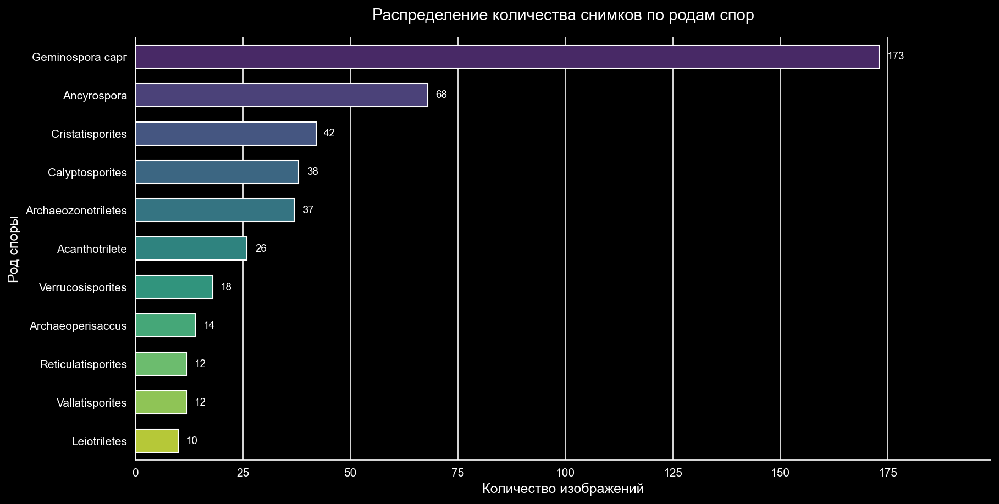

In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Базовый путь к датасету
data_dir_path = DATA_DIR
valid_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

class_counts = {}

# Обходим только подпапки первого уровня (каждая папка = Род)
for genus_dir in data_dir_path.iterdir():
    if genus_dir.is_dir():
        genus_name = genus_dir.name

        # Рекурсивно считаем все снимки во всех видовых подпапках данного рода
        img_count = sum(
            1 for file_path in genus_dir.rglob('*')
            if file_path.suffix.lower() in valid_extensions
        )

        if img_count > 0:
            class_counts[genus_name] = img_count

# Формируем DataFrame
df_stats = pd.DataFrame(list(class_counts.items()), columns=['Род споры', 'Количество'])
df_stats = df_stats.sort_values(by='Количество', ascending=False).reset_index(drop=True)

num_classes = len(df_stats)
print(f"Всего найдено родов (классов): {num_classes}")
print(f"Общее количество снимков: {df_stats['Количество'].sum()}")

# --- Настройка адаптивного размера графика ---
fig_height = max(6, num_classes * 0.4)

plt.figure(figsize=(12, fig_height), layout='constrained')

# Рисуем горизонтальный график
ax = sns.barplot(
    data=df_stats,
    x='Количество',
    y='Род споры',
    hue='Род споры',
    palette='viridis',
    legend=False,
    width=0.6
)

# Добавляем точные значения цифрами справа от каждого столбца
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f'{int(width)}',
            (width, p.get_y() + p.get_height() / 2.),
            ha='left',
            va='center',
            xytext=(7, 0),
            textcoords='offset points',
            fontsize=9
        )

# Настройка заголовков и осей
plt.title('Распределение количества снимков по родам спор', fontsize=14, pad=15)
plt.xlabel('Количество изображений', fontsize=12)
plt.ylabel('Род споры', fontsize=12)

# Добавляем пространство справа под текстовые метки
ax.set_xlim(0, df_stats['Количество'].max() * 1.15)

# Убираем лишние рамки
sns.despine(top=True, right=True)

plt.show()


[INFO] Каталог: data\Geminospora сарг | Отобрано файлов: 5 (лимит: 5)

 ОБРАБОТКА [1 | Geminospora]: G. aurita   100-1 037.jpg
 ФАЙЛ ЗАПРОСА : G. aurita   100-1 037.jpg (Род: Geminospora)
  #1 | Сходство: 0.798 | Род: Geminospora          | Файл: Geminospora micromanifesta Ср Тим  обр Р2-5 006.jpg
  #2 | Сходство: 0.796 | Род: Leiotriletes         | Файл: Leiotriletes nigratus Ср Тим  обр Р2-3 016.jpg
  #3 | Сходство: 0.792 | Род: Geminospora          | Файл: G. micromanifestava var. limbatus 138-1 030.jpg
  #4 | Сходство: 0.781 | Род: Geminospora          | Файл: Geminospora micromanifesta Ср Тим  обр Р2-3 013.jpg
  #5 | Сходство: 0.778 | Род: Archaeozonotriletes  | Файл: Archaeozonotriletes variabilis var. insignis 419-1 035.jpg


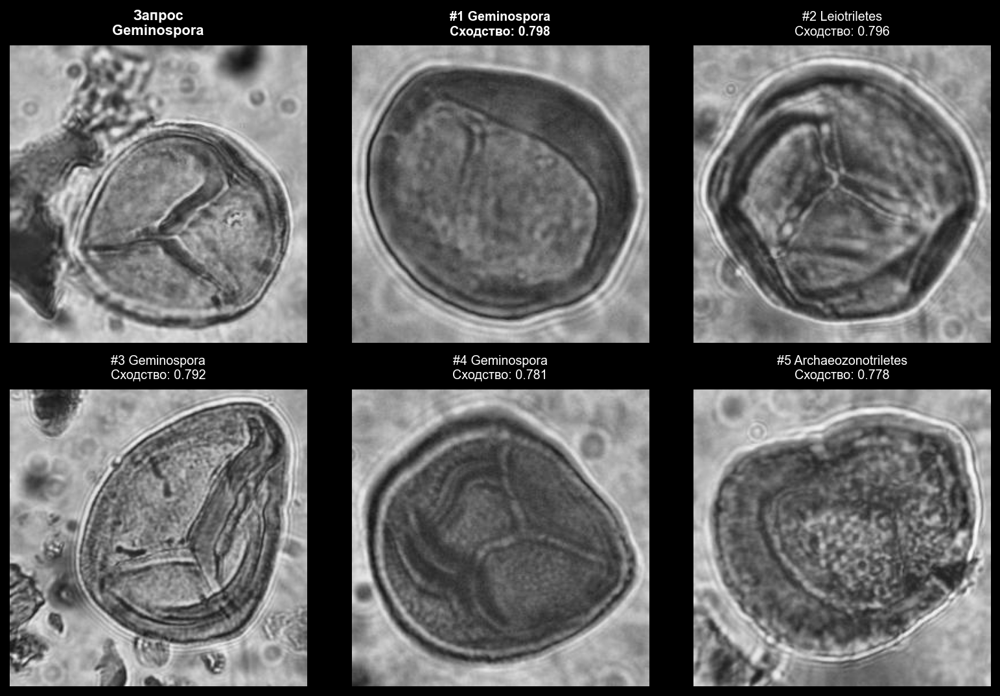


 ОБРАБОТКА [2 | Geminospora]: G. aurita  154-1 051.jpg
 ФАЙЛ ЗАПРОСА : G. aurita  154-1 051.jpg (Род: Geminospora)
  #1 | Сходство: 0.706 | Род: Geminospora          | Файл: G. micromanifesta 154-1 022.jpg
  #2 | Сходство: 0.701 | Род: Geminospora          | Файл: G. micromanifesta var. collatatus 79-1 035.jpg
  #3 | Сходство: 0.693 | Род: Geminospora          | Файл: G.micromanifesta  var. acanthinus 96-1 004.jpg
  #4 | Сходство: 0.686 | Род: Geminospora          | Файл: G. micromanifesta 368-1 002.jpg
  #5 | Сходство: 0.642 | Род: Geminospora          | Файл: G. micromanifesta 109-3 003.jpg


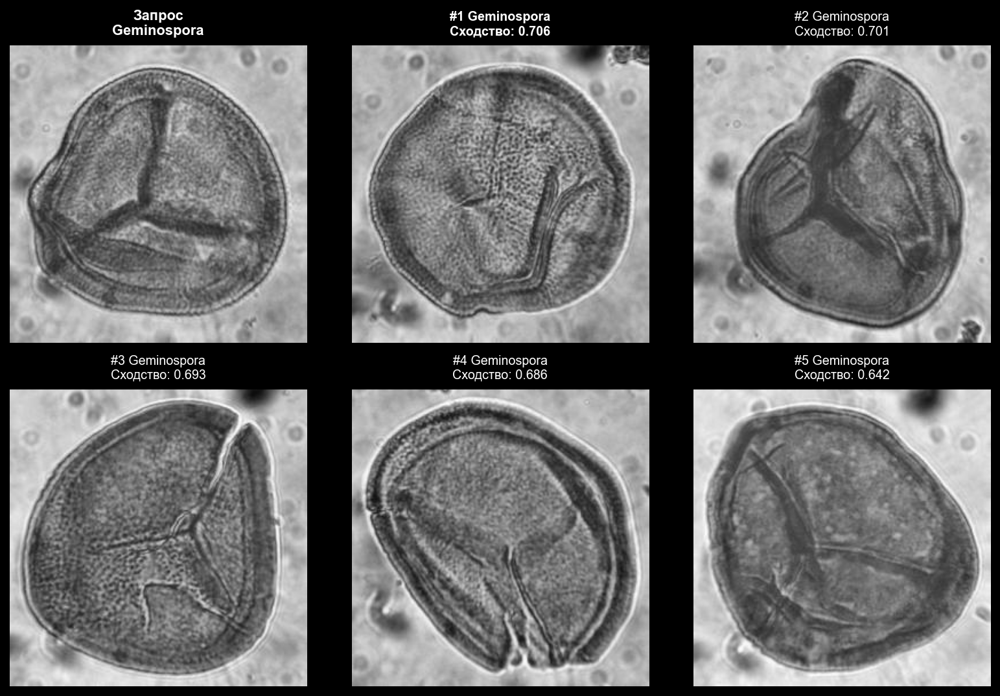


 ОБРАБОТКА [3 | Geminospora]: G. aurita T560.jpg
 ФАЙЛ ЗАПРОСА : G. aurita T560.jpg (Род: Geminospora)
  #1 | Сходство: 0.515 | Род: Geminospora          | Файл: G. micromanifesta  var. copiosus  210-2 023.jpg
  #2 | Сходство: 0.512 | Род: Archaeozonotriletes  | Файл: Archaeozonotriletes tschernovii 368-1 066.jpg
  #3 | Сходство: 0.478 | Род: Geminospora          | Файл: G. micromanifesta Ср Тим с 6.jpg
  #4 | Сходство: 0.462 | Род: Leiotriletes         | Файл: Leiotriletes nigratus Ср Тим  обр Р2-3 071.jpg
  #5 | Сходство: 0.443 | Род: Geminospora          | Файл: G. micromanifestava var. limbatus 138-1 047.jpg


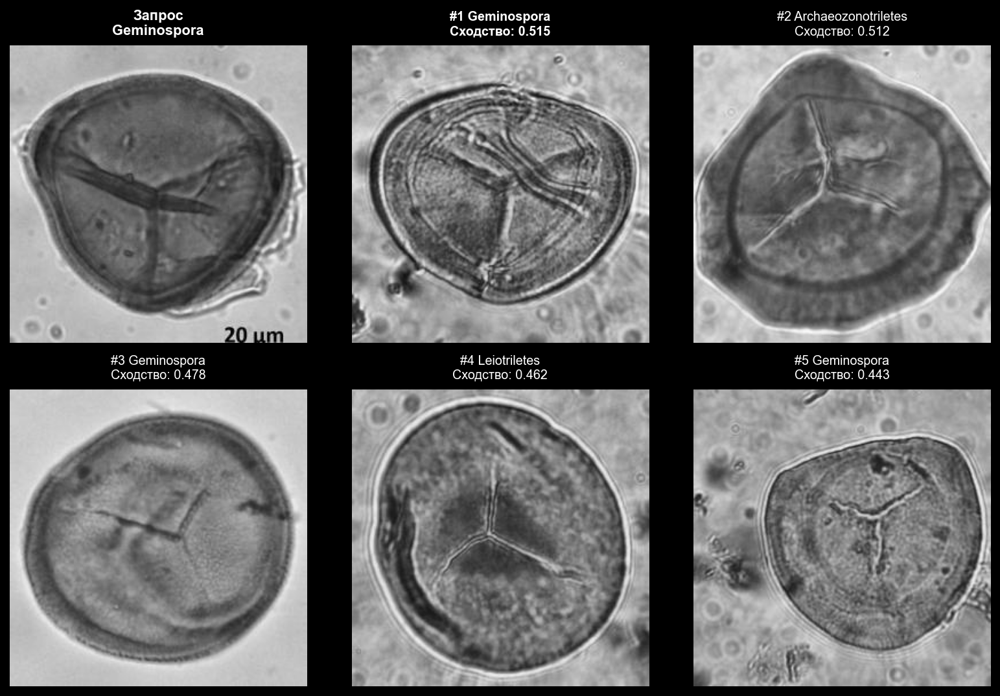


 ОБРАБОТКА [4 | Geminospora]: G. aurita V620.jpg
 ФАЙЛ ЗАПРОСА : G. aurita V620.jpg (Род: Geminospora)
  #1 | Сходство: 0.815 | Род: Archaeozonotriletes  | Файл: Archaeozonotriletes variabilis var. insignis 419-1 035.jpg
  #2 | Сходство: 0.815 | Род: Geminospora          | Файл: G. micromanifesta 419-1 035.jpg
  #3 | Сходство: 0.810 | Род: Geminospora          | Файл: G. sp. 89-1 004.jpg
  #4 | Сходство: 0.809 | Род: Geminospora          | Файл: G. aurita Ср Тим 170 с1 U570.jpg
  #5 | Сходство: 0.807 | Род: Geminospora          | Файл: Geminospora micromanifesta Ср Тим  обр Р2-3 013.jpg


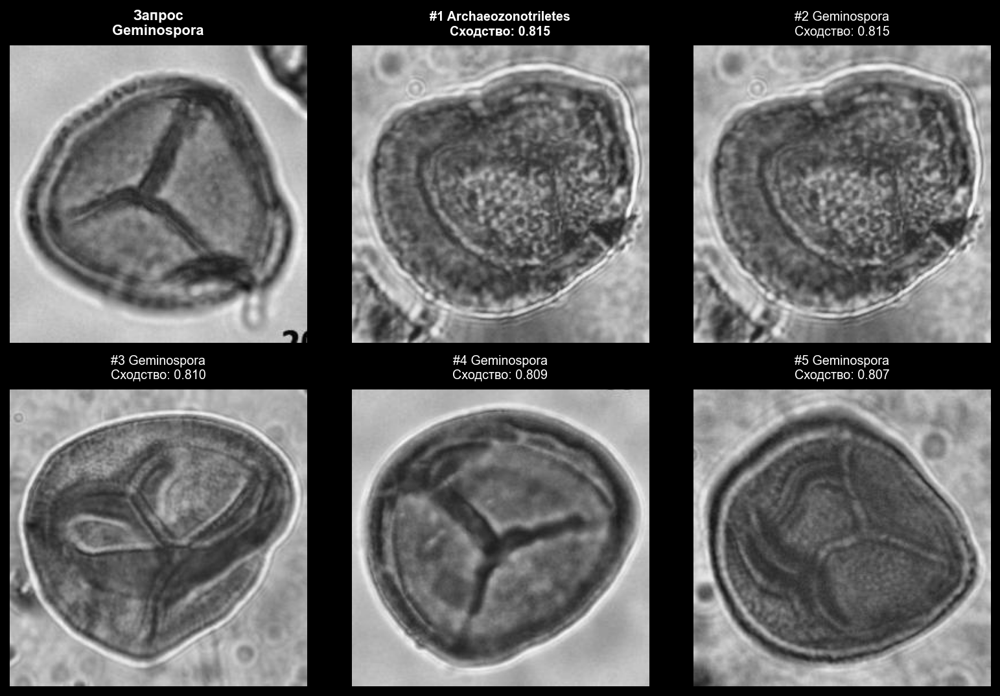


 ОБРАБОТКА [5 | Geminospora]: G. aurita Ср Тим  обр 315-1 016.jpg
 ФАЙЛ ЗАПРОСА : G. aurita Ср Тим  обр 315-1 016.jpg (Род: Geminospora)
  #1 | Сходство: 0.233 | Род: Archaeozonotriletes  | Файл: Archaeozonotriletes timanicus 100-1 023.jpg
  #2 | Сходство: 0.219 | Род: Geminospora          | Файл: G. plicata 109-3.jpg
  #3 | Сходство: 0.208 | Род: Geminospora          | Файл: G. micromanifesta 419-1 034.jpg
  #4 | Сходство: 0.208 | Род: Archaeozonotriletes  | Файл: Archaeozonotriletes variabilis var. insignis 419-1 034.jpg
  #5 | Сходство: 0.205 | Род: Verrucosisporites    | Файл: V. grumosus V900.jpg


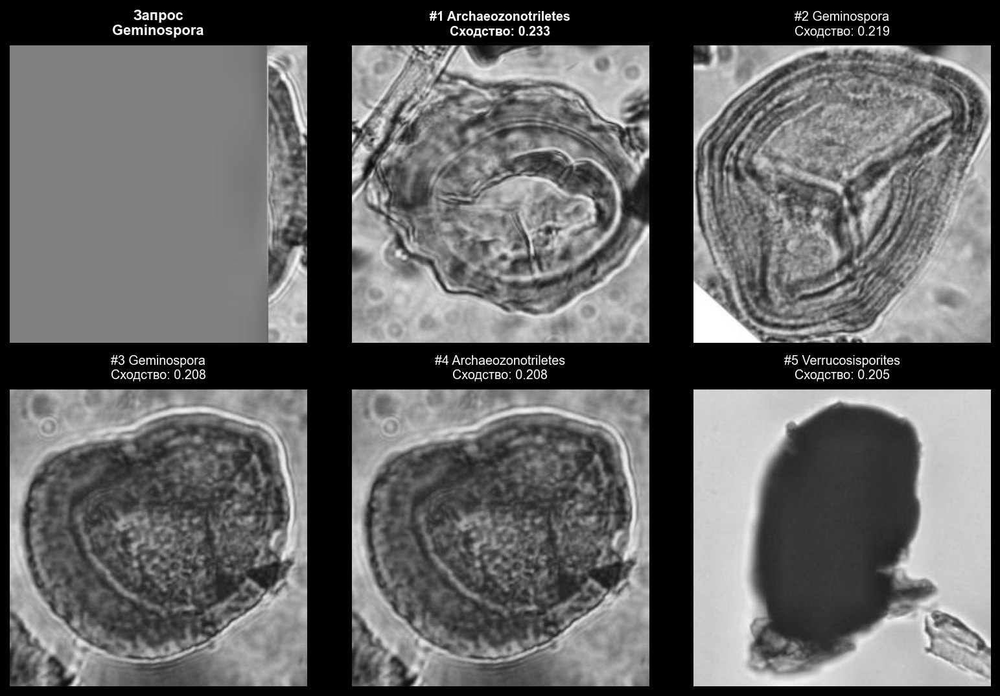


[INFO] Каталог: data\Leiotriletes | Отобрано файлов: 5 (лимит: 5)

 ОБРАБОТКА [6 | Leiotriletes]: Leiotriletes atavus Ср Тим  обр Р2-2 026.jpg
 ФАЙЛ ЗАПРОСА : Leiotriletes atavus Ср Тим  обр Р2-2 026.jpg (Род: Leiotriletes)
  #1 | Сходство: 0.782 | Род: Geminospora          | Файл: Geminospora micromanifesta Ср Тим  обр Р2-5 006.jpg
  #2 | Сходство: 0.683 | Род: Geminospora          | Файл: G. micromanifestava var. limbatus 138-1 047.jpg
  #3 | Сходство: 0.678 | Род: Geminospora          | Файл: G. aurita   100-1 037.jpg
  #4 | Сходство: 0.676 | Род: Archaeozonotriletes  | Файл: Archaeozonotriletes timanicus Ср Тим обр Р2-5 024.jpg
  #5 | Сходство: 0.668 | Род: Geminospora          | Файл: G. aurita Ср Тим 326-1 018.jpg


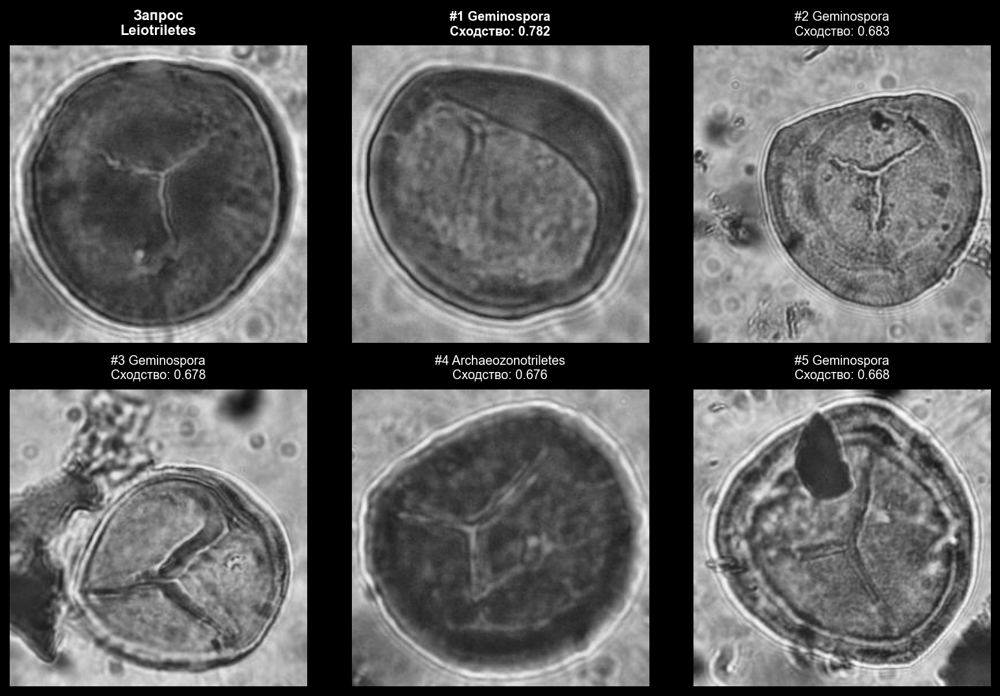


 ОБРАБОТКА [7 | Leiotriletes]: Leiotriletes atavus Ср Тим  обр Р2-2 027.jpg
 ФАЙЛ ЗАПРОСА : Leiotriletes atavus Ср Тим  обр Р2-2 027.jpg (Род: Leiotriletes)
  #1 | Сходство: 0.647 | Род: Leiotriletes         | Файл: Leiotriletes atavus Ср Тим  обр Р2-2 026.jpg
  #2 | Сходство: 0.646 | Род: Geminospora          | Файл: Geminospora micromanifesta Ср Тим  обр Р2-3 004.jpg
  #3 | Сходство: 0.642 | Род: Leiotriletes         | Файл: Leiotriletes nigratus Ср Тим  обр Р2-2 052.jpg
  #4 | Сходство: 0.633 | Род: Leiotriletes         | Файл: Leiotriletes nigratus Ср Тим  обр Р2-2 051.jpg
  #5 | Сходство: 0.574 | Род: Leiotriletes         | Файл: Leiotriletes nigratus Ср Тим  обр Р2-3 072.jpg


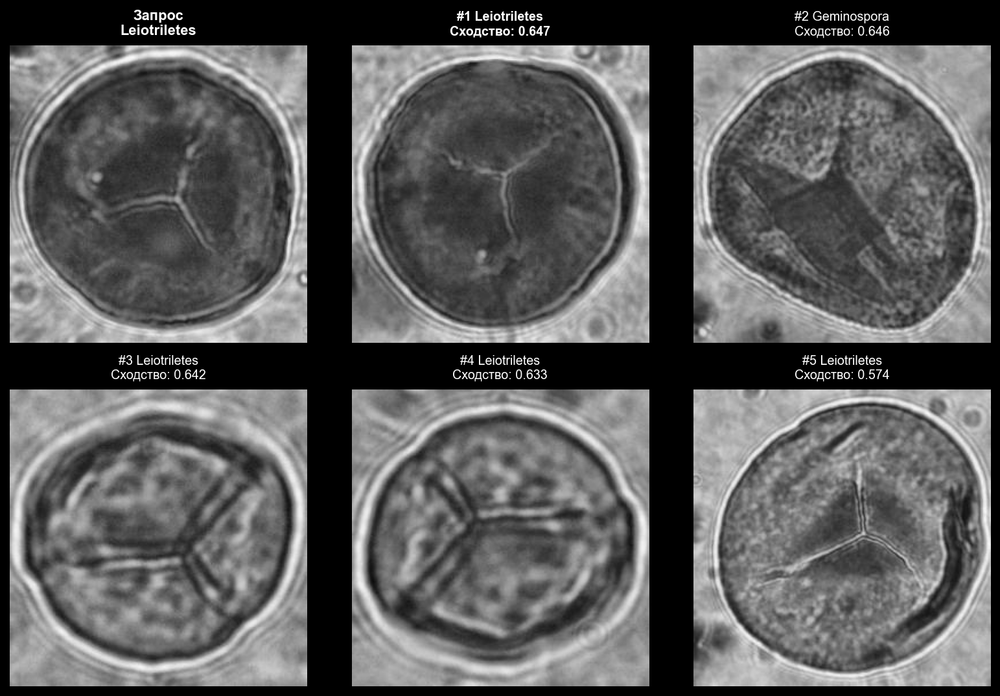


 ОБРАБОТКА [8 | Leiotriletes]: Leiotriletes nigratus Ср Тим  обр Р2-2 051.jpg
 ФАЙЛ ЗАПРОСА : Leiotriletes nigratus Ср Тим  обр Р2-2 051.jpg (Род: Leiotriletes)
  #1 | Сходство: 0.921 | Род: Leiotriletes         | Файл: Leiotriletes nigratus Ср Тим  обр Р2-2 052.jpg
  #2 | Сходство: 0.633 | Род: Leiotriletes         | Файл: Leiotriletes atavus Ср Тим  обр Р2-2 027.jpg
  #3 | Сходство: 0.557 | Род: Acanthotrilete       | Файл: Acanthotriletes eximius Ср Тим  обр Р2-2 008.jpg
  #4 | Сходство: 0.469 | Род: Geminospora          | Файл: G. micromanifesta  var. collatatus 100-1 001.jpg
  #5 | Сходство: 0.411 | Род: Archaeozonotriletes  | Файл: Archaeozonotriletes timanicus 419-1 074.jpg


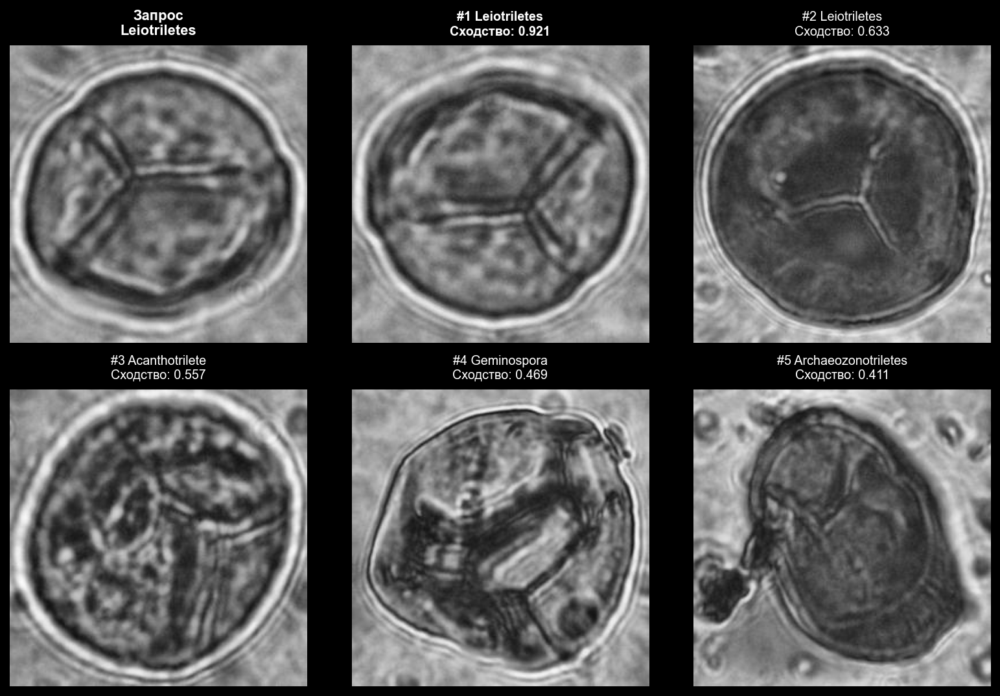


 ОБРАБОТКА [9 | Leiotriletes]: Leiotriletes nigratus Ср Тим  обр Р2-2 052.jpg
 ФАЙЛ ЗАПРОСА : Leiotriletes nigratus Ср Тим  обр Р2-2 052.jpg (Род: Leiotriletes)
  #1 | Сходство: 0.921 | Род: Leiotriletes         | Файл: Leiotriletes nigratus Ср Тим  обр Р2-2 051.jpg
  #2 | Сходство: 0.642 | Род: Leiotriletes         | Файл: Leiotriletes atavus Ср Тим  обр Р2-2 027.jpg
  #3 | Сходство: 0.546 | Род: Acanthotrilete       | Файл: Acanthotriletes eximius Ср Тим  обр Р2-2 008.jpg
  #4 | Сходство: 0.446 | Род: Geminospora          | Файл: G. micromanifesta  var. collatatus 100-1 001.jpg
  #5 | Сходство: 0.393 | Род: Archaeozonotriletes  | Файл: Archaeozonotriletes timanicus 419-1 074.jpg


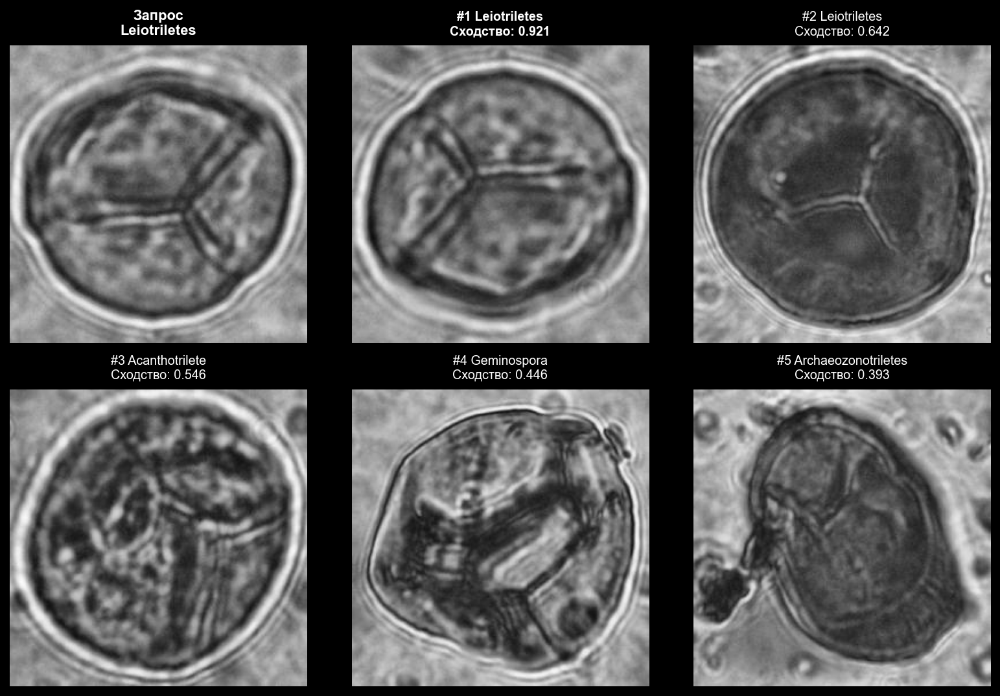


 ОБРАБОТКА [10 | Leiotriletes]: Leiotriletes nigratus Ср Тим  обр Р2-3 015.jpg
 ФАЙЛ ЗАПРОСА : Leiotriletes nigratus Ср Тим  обр Р2-3 015.jpg (Род: Leiotriletes)
  #1 | Сходство: 0.931 | Род: Leiotriletes         | Файл: Leiotriletes nigratus Ср Тим  обр Р2-3 016.jpg
  #2 | Сходство: 0.857 | Род: Geminospora          | Файл: Geminospora micromanifesta Ср Тим  обр Р2-3 013.jpg
  #3 | Сходство: 0.855 | Род: Archaeozonotriletes  | Файл: Archaeozonotriletes timanicus Ср Тим обр Р2-5 024.jpg
  #4 | Сходство: 0.849 | Род: Geminospora          | Файл: G. sp. 89-1 004.jpg
  #5 | Сходство: 0.824 | Род: Geminospora          | Файл: G. plicata  109-3 004.jpg


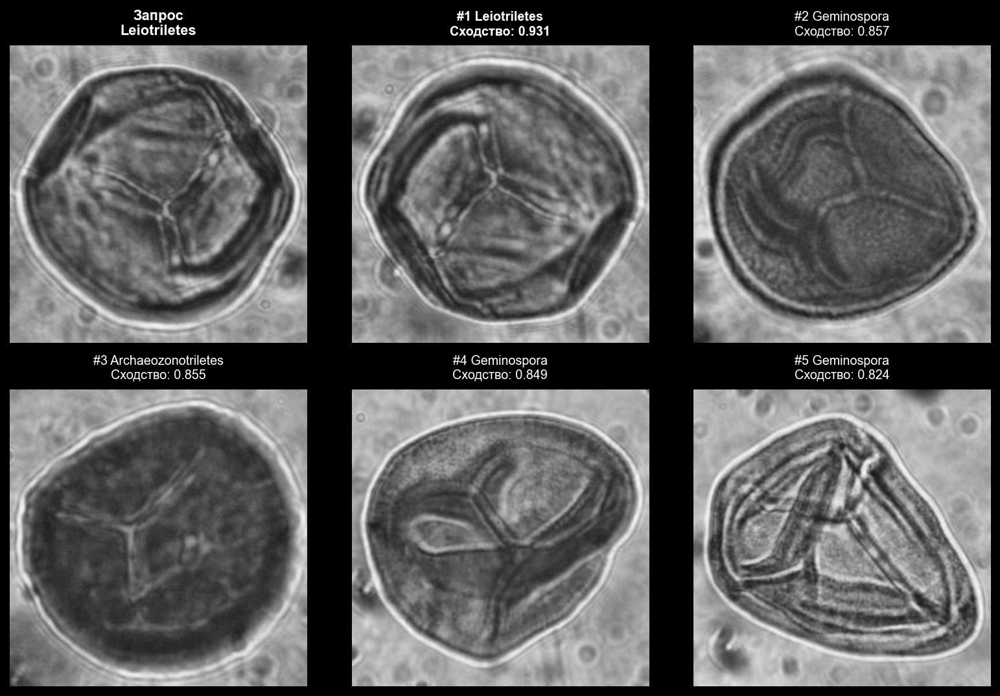


[SUCCESS] Итоговый отчёт сохранён в файл:
reports\spore_report.docx


In [9]:
import io
import math
from pathlib import Path

from docx import Document
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.shared import Inches, Pt
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix


def first_word(raw_name, fallback="Geminospora"):
    """Возвращает только первое слово названия (например, 'Geminospora сарг' -> 'Geminospora')."""
    if not raw_name:
        return fallback
    parts = str(raw_name).strip().split()
    return parts[0] if parts else fallback


def resolve_folder_path(target_path, base_root=DATA_DIR):
    """Находит существующий путь к каталогу (с учётом возможной разницы в суффиксе/раскладке)."""
    p = Path(target_path)
    if p.exists():
        return p

    parent = p.parent if p.parent.exists() else base_root
    prefix = first_word(p.name, fallback="").lower()
    if parent and parent.exists() and prefix:
        for candidate in parent.iterdir():
            if candidate.is_dir() and candidate.name.lower().startswith(prefix):
                return candidate
    return p


def get_genus_label(file_path, base_root=None, fallback="Geminospora"):
    """Определяет род по пути к файлу и возвращает только первое слово для подписей."""
    p = Path(file_path)

    if base_root is not None:
        root_p = Path(base_root)
        try:
            rel = p.relative_to(root_p)
            if len(rel.parts) >= 2:
                return first_word(root_p.name, fallback=fallback)
        except ValueError:
            pass

    if len(p.parents) >= 3 and p.parents[1].name:
        return first_word(p.parents[1].name, fallback=fallback)
    if len(p.parents) >= 2 and p.parent.name:
        return first_word(p.parent.name, fallback=fallback)

    return fallback


def collect_spore_files(folder_path, valid_extensions, limit=None):
    """Собирает файлы изображений из каталога (включая подпапки) с ограничением числа экземпляров."""
    files = sorted([
        p for p in Path(folder_path).rglob("*")
        if p.is_file() and p.suffix.lower() in valid_extensions
    ])
    if limit is not None:
        return files[:limit]
    return files


def build_and_display_result_figure(query_pil, results, query_path=None, base_root=None, show_inline=True):
    """Формирует сетку 2x3 на чёрном фоне с белыми подписями (только род и сходство)."""
    total_items = len(results) + 1
    rows = 2
    cols = math.ceil(total_items / rows)

    fig, axes = plt.subplots(rows, cols, figsize=(3.6 * cols, 7.4), facecolor="black")
    fig.patch.set_facecolor("black")

    if isinstance(axes, np.ndarray):
        axes = axes.flatten()
    else:
        axes = [axes]

    query_genus = (
        get_genus_label(query_path, base_root=base_root, fallback="Geminospora")
        if query_path
        else "Geminospora"
    )
    query_rgb = query_pil.convert("RGB")
    axes[0].set_facecolor("black")
    axes[0].imshow(query_rgb)
    axes[0].set_title(
        f"Запрос\n{query_genus}",
        fontsize=10.5,
        fontweight="bold",
        color="white",
        backgroundcolor="black",
        pad=8,
    )
    axes[0].axis("off")

    for i, res in enumerate(results):
        match_path = Path(res["path"])
        raw_genus = res.get("genus")
        genus_label = (
            first_word(raw_genus, fallback=query_genus)
            if raw_genus
            else get_genus_label(match_path, base_root=base_root, fallback=query_genus)
        )

        try:
            with Image.open(match_path) as img:
                match_pil = img.convert("RGB")
        except Exception as e:
            print(f"[ERROR] Не удалось загрузить файл {match_path}: {e}")
            match_pil = Image.new("RGB", (256, 256), color="dimgray")

        ax = axes[i + 1]
        ax.set_facecolor("black")
        ax.imshow(match_pil)

        ax.set_title(
            f"#{i+1} {genus_label}\nСходство: {res['score']:.3f}",
            fontsize=9.5,
            fontweight="bold" if i == 0 else "normal",
            color="white",
            backgroundcolor="black",
            pad=8,
        )
        ax.axis("off")

    for j in range(total_items, len(axes)):
        axes[j].set_facecolor("black")
        axes[j].axis("off")

    plt.tight_layout(pad=1.8)

    img_buffer = io.BytesIO()
    fig.savefig(img_buffer, format="png", dpi=150, facecolor="black", bbox_inches="tight")
    img_buffer.seek(0)

    if show_inline:
        plt.show()

    plt.close(fig)
    return img_buffer


def build_recall_confusion_matrix_figure(y_true, y_pred, class_names, show_inline=True):
    """Строит матрицу ошибок, нормированную по строкам (по диагонали — Recall каждого рода)."""
    cm_recall = confusion_matrix(y_true, y_pred, labels=class_names, normalize="true")
    cm_recall = np.nan_to_num(cm_recall, nan=0.0)

    n = len(class_names)
    fig_size = max(6.5, 1.1 * n)
    fig, ax = plt.subplots(figsize=(fig_size, fig_size * 0.85), facecolor="black")
    ax.set_facecolor("black")

    im = ax.imshow(cm_recall, cmap="magma", vmin=0.0, vmax=1.0)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.yaxis.set_tick_params(color="white")
    plt.setp(plt.getp(cbar.ax.axes, "yticklabels"), color="white")
    cbar.set_label("Recall (доля верных предсказаний в классе)", color="white", fontsize=9.5)

    ax.set_xticks(np.arange(n))
    ax.set_yticks(np.arange(n))
    ax.set_xticklabels(class_names, rotation=30, ha="right", color="white", fontsize=9.5)
    ax.set_yticklabels(class_names, color="white", fontsize=9.5)

    ax.set_xlabel("Предсказанный род (Top-1)", color="white", fontsize=10.5, fontweight="bold", labelpad=10)
    ax.set_ylabel("Истинный род", color="white", fontsize=10.5, fontweight="bold", labelpad=10)
    ax.set_title(
        "Матрица ошибок по полноте (Recall Confusion Matrix)",
        color="white",
        fontsize=12,
        fontweight="bold",
        pad=14,
    )

    for r in range(n):
        for c in range(n):
            val = cm_recall[r, c]
            text_color = "black" if val > 0.55 else "white"
            ax.text(
                c,
                r,
                f"{val:.3f}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=9,
                fontweight="bold" if r == c else "normal",
            )

    plt.tight_layout()

    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=150, facecolor="black", bbox_inches="tight")
    buf.seek(0)

    if show_inline:
        plt.show()

    plt.close(fig)
    return buf


def add_styled_table(doc, headers, rows_data, font_size=9):
    """Добавляет аккуратную таблицу в документ Word."""
    table = doc.add_table(rows=1, cols=len(headers))
    table.style = "Table Grid"

    hdr_cells = table.rows[0].cells
    for col_idx, text in enumerate(headers):
        hdr_cells[col_idx].text = str(text)
        for p in hdr_cells[col_idx].paragraphs:
            for r in p.runs:
                r.font.bold = True
                r.font.size = Pt(font_size + 0.5)

    for row_vals in rows_data:
        row_cells = table.add_row().cells
        for col_idx, val in enumerate(row_vals):
            row_cells[col_idx].text = str(val)
            for p in row_cells[col_idx].paragraphs:
                for r in p.runs:
                    r.font.size = Pt(font_size)

    return table


def process_genus_batch(
    genus_folder,
    base_root,
    doc,
    valid_extensions,
    limit=5,
    start_index=1,
    show_inline=True,
):
    """Выполняет пакетный поиск Top-5 для одного рода и записывает результаты в Word."""
    y_true = []
    y_pred = []
    top1_scores = []
    current_idx = start_index

    if not genus_folder.exists():
        print(f"[WARN] Каталог не найден, пропущен: {genus_folder}")
        p_warn = doc.add_paragraph()
        p_warn.add_run(f"[Каталог не найден: {genus_folder}]").italic = True
        return current_idx, y_true, y_pred, top1_scores

    spore_files = collect_spore_files(genus_folder, valid_extensions, limit=limit)
    expected_genus = first_word(genus_folder.name, fallback=genus_folder.name)

    print(f"\n[INFO] Каталог: {genus_folder} | Отобрано файлов: {len(spore_files)} (лимит: {limit})")

    for query_path in spore_files:
        print(f"\n============================================================")
        print(f" ОБРАБОТКА [{current_idx} | {expected_genus}]: {query_path.name}")
        print(f"============================================================")

        try:
            query_pil, raw_results = search_similar_spores(
                str(query_path),
                vectors,
                labels,
                paths,
                extractor,
                top_k=6,
                is_processed=True,
            )

            top5_similar = raw_results[1:6]
            if not top5_similar:
                print(f"[WARN] Для {query_path.name} не найдено совпадений.")
                current_idx += 1
                continue

            query_genus_label = get_genus_label(query_path, base_root=genus_folder, fallback=expected_genus)
            top1_res = top5_similar[0]
            raw_top1_genus = top1_res.get("genus")
            pred_genus_label = (
                first_word(raw_top1_genus, fallback=query_genus_label)
                if raw_top1_genus
                else get_genus_label(top1_res["path"], base_root=base_root, fallback=query_genus_label)
            )

            y_true.append(query_genus_label)
            y_pred.append(pred_genus_label)
            top1_scores.append(float(top1_res["score"]))

            print(f" ФАЙЛ ЗАПРОСА : {query_path.name} (Род: {query_genus_label})")
            for rank, res in enumerate(top5_similar, 1):
                m_path = Path(res["path"])
                raw_g = res.get("genus")
                g_label = (
                    first_word(raw_g, fallback=query_genus_label)
                    if raw_g
                    else get_genus_label(m_path, base_root=base_root, fallback=query_genus_label)
                )
                print(f"  #{rank} | Сходство: {res['score']:.3f} | Род: {g_label:<20} | Файл: {m_path.name}")

            fig_buffer = build_and_display_result_figure(
                query_pil,
                top5_similar,
                query_path=query_path,
                base_root=genus_folder,
                show_inline=show_inline,
            )

            doc.add_heading(f"{current_idx}. Запрос ({query_genus_label}): {query_path.name}", level=1)

            p_sub = doc.add_paragraph()
            p_sub.add_run("Род запроса: ").bold = True
            p_sub.add_run(f"{query_genus_label}   |   ")
            p_sub.add_run("Top-1 род: ").bold = True
            p_sub.add_run(f"{pred_genus_label} (сходство: {top1_res['score']:.4f})")

            rows_table = []
            for rank, res in enumerate(top5_similar, 1):
                m_path = Path(res["path"])
                raw_g = res.get("genus")
                g_label = (
                    first_word(raw_g, fallback=query_genus_label)
                    if raw_g
                    else get_genus_label(m_path, base_root=base_root, fallback=query_genus_label)
                )
                rows_table.append([f"#{rank}", g_label, f"{res['score']:.4f}", m_path.name])

            add_styled_table(
                doc,
                headers=["Ранг", "Род", "Сходство", "Имя файла результата"],
                rows_data=rows_table,
                font_size=9,
            )

            doc.add_paragraph()

            p_img = doc.add_paragraph()
            p_img.alignment = WD_ALIGN_PARAGRAPH.CENTER
            run_img = p_img.add_run()
            run_img.add_picture(fig_buffer, width=Inches(6.2))
            fig_buffer.close()

            doc.add_page_break()
            current_idx += 1

        except Exception as e:
            print(f"[ERROR] Ошибка при обработке файла {query_path.name}: {e}")
            p_err = doc.add_paragraph()
            p_err.add_run(f"[Ошибка при обработке {query_path.name}: {e}]").italic = True
            doc.add_page_break()
            current_idx += 1

    return current_idx, y_true, y_pred, top1_scores


# ==============================================================================
# ОСНОВНОЙ ПАЙПЛАЙН: GEMINOSPORA (5 шт.) + LEOTRILETES + МЕТРИКИ + ВЫВОДЫ
# ==============================================================================

base_crop_root = DATA_DIR
geminospora_folder = resolve_folder_path(
    DATA_DIR / "Geminospora сарг",
    base_root=base_crop_root,
)
leotriletes_folder = resolve_folder_path(
    DATA_DIR / "Leiotriletes",
    base_root=base_crop_root,
)
output_docx_path = OUTPUT_DOCX

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

doc = Document()
doc.add_heading("Отчёт по поиску похожих спор и оценке классификации (Top-1)", level=0)

p_meta = doc.add_paragraph()
p_meta.add_run("Каталог Geminospora: ").bold = True
p_meta.add_run(f"{geminospora_folder} (лимит: 5 экземпляров)\n")
p_meta.add_run("Каталог Leotriletes: ").bold = True
p_meta.add_run(f"{leotriletes_folder}\n")
doc.add_page_break()

all_y_true = []
all_y_pred = []
all_top1_scores = []
next_idx = 1

# 1. Пакетный поиск для Geminospora (ровно до 5 экземпляров)
next_idx, g_true, g_pred, g_scores = process_genus_batch(
    genus_folder=geminospora_folder,
    base_root=base_crop_root,
    doc=doc,
    valid_extensions=valid_extensions,
    limit=5,
    start_index=next_idx,
    show_inline=True,
)
all_y_true.extend(g_true)
all_y_pred.extend(g_pred)
all_top1_scores.extend(g_scores)

# 2. Пакетный поиск для Leotriletes
next_idx, l_true, l_pred, l_scores = process_genus_batch(
    genus_folder=leotriletes_folder,
    base_root=base_crop_root,
    doc=doc,
    valid_extensions=valid_extensions,
    limit=5,
    start_index=next_idx,
    show_inline=True,
)
all_y_true.extend(l_true)
all_y_pred.extend(l_pred)
all_top1_scores.extend(l_scores)

output_docx_path.parent.mkdir(parents=True, exist_ok=True)
doc.save(str(output_docx_path))
print(f"\n[SUCCESS] Итоговый отчёт сохранён в файл:\n{output_docx_path}")


 ПРОВЕРКА НОРМЫ ВЕКТОРОВ ПРИЗНАКОВ
 Средняя норма : 1.000000 (min=1.000000, max=1.000000)
 Единичная норма (atol=0.001): ДА
 Норма после деления: min=1.000000, max=1.000000

[INFO] Найдено родов: 11. Всего образцов: 450

 МЕТРИКИ ТОЧНОСТИ ПОИСКА ПО РОДАМ (Top-K Accuracy)
 Top-1 Accuracy: 72.00% (324/450)
 Top-3 Accuracy: 88.00% (396/450)
 Top-5 Accuracy: 92.67% (417/450)


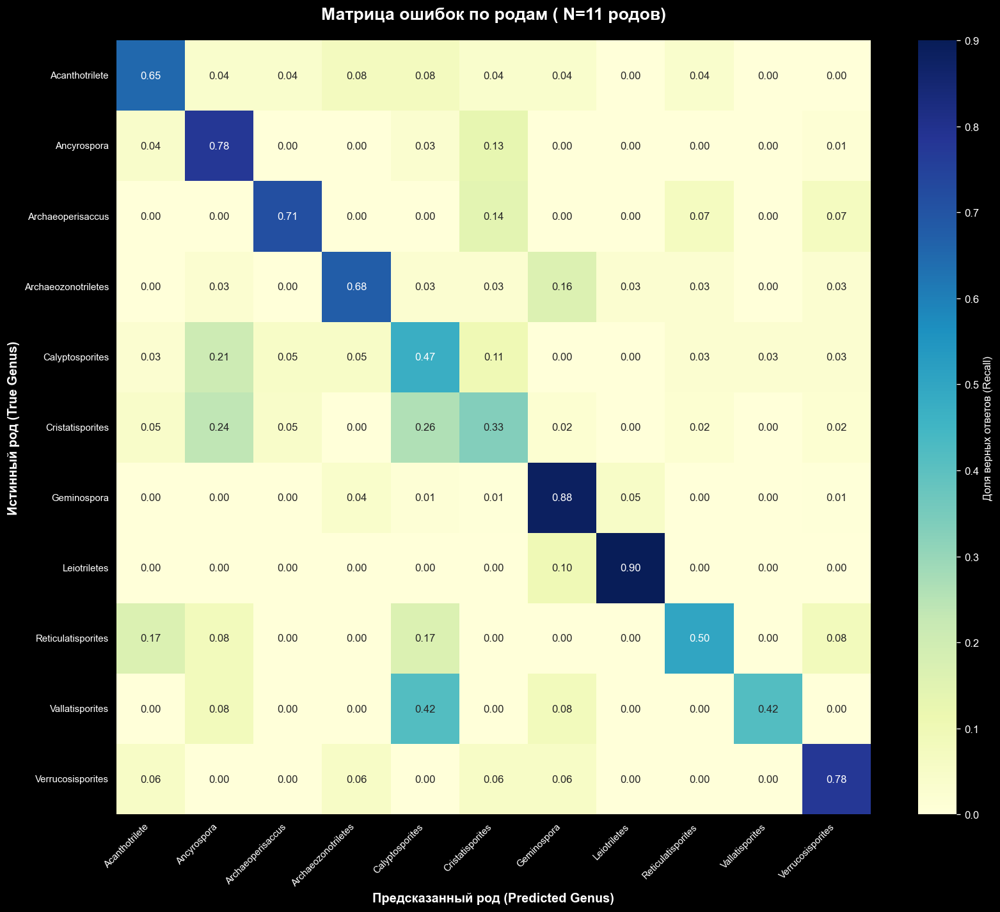


 ПОДРОБНЫЙ ОТЧЕТ ПО РОДАМ (Top-1)
                     precision    recall  f1-score   support

     Acanthotrilete     0.6538    0.6538    0.6538        26
        Ancyrospora     0.7067    0.7794    0.7413        68
  Archaeoperisaccus     0.6667    0.7143    0.6897        14
Archaeozonotriletes     0.6757    0.6757    0.6757        37
    Calyptosporites     0.4186    0.4737    0.4444        38
   Cristatisporites     0.4242    0.3333    0.3733        42
        Geminospora     0.9329    0.8844    0.9080       173
       Leiotriletes     0.4737    0.9000    0.6207        10
 Reticulatisporites     0.5455    0.5000    0.5217        12
    Vallatisporites     0.8333    0.4167    0.5556        12
  Verrucosisporites     0.6667    0.7778    0.7179        18

           accuracy                         0.7200       450
          macro avg     0.6362    0.6463    0.6275       450
       weighted avg     0.7284    0.7200    0.7195       450


[SUCCESS] Отчёт сохранён в Word: reports\confu

In [10]:
import io
from pathlib import Path

from docx import Document
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.shared import Inches, Pt
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix


def clean_genus_label(label):
    path_parts = Path(label).parts
    if path_parts:
        label = path_parts[0]
    return label.strip().split()[0].capitalize()


def evaluate_and_plot_confusion_matrix_large(
    db_vectors,
    db_labels,
    top_k_eval=(1, 3, 5),
    output_docx_path=BASE_DIR / "reports" / "confusion_matrix_and_reports.docx",
    norm_tol=1e-3,
):
    vectors_arr = np.asarray(db_vectors, dtype=np.float32)
    if vectors_arr.size == 0 or len(vectors_arr) == 0:
        print("[ERROR] База данных пуста!")
        return None

    # 1. Проверка нормы векторов и деление на норму (L2-нормализация)
    norms = np.linalg.norm(vectors_arr, axis=1, keepdims=True)
    flat_norms = norms.ravel()
    min_norm = float(np.min(flat_norms))
    max_norm = float(np.max(flat_norms))
    mean_norm = float(np.mean(flat_norms))
    is_unit_norm = bool(np.allclose(flat_norms, 1.0, atol=norm_tol))

    print("\n" + "=" * 50)
    print(" ПРОВЕРКА НОРМЫ ВЕКТОРОВ ПРИЗНАКОВ")
    print("=" * 50)
    print(f" Средняя норма : {mean_norm:.6f} (min={min_norm:.6f}, max={max_norm:.6f})")
    print(f" Единичная норма (atol={norm_tol}): {'ДА' if is_unit_norm else 'НЕТ — выполняется деление на норму'}")

    safe_norms = np.maximum(norms, 1e-12)
    norm_vectors = vectors_arr / safe_norms

    after_norms = np.linalg.norm(norm_vectors, axis=1)
    print(
        f" Норма после деления: min={float(np.min(after_norms)):.6f}, "
        f"max={float(np.max(after_norms)):.6f}"
    )

    cleaned_labels = np.array([clean_genus_label(lbl) for lbl in db_labels])
    classes = sorted(list(set(cleaned_labels)))
    n_classes = len(classes)

    print(f"\n[INFO] Найдено родов: {n_classes}. Всего образцов: {len(norm_vectors)}")

    # 2. Матрица косинусного сходства по нормированным векторам
    sim_matrix = np.dot(norm_vectors, norm_vectors.T)
    np.fill_diagonal(sim_matrix, -1.0)

    y_true = cleaned_labels
    y_pred_top1 = []
    top_k_hits = {k: 0 for k in top_k_eval}
    sample_predictions = []

    for i in range(len(norm_vectors)):
        sorted_indices = np.argsort(sim_matrix[i])[::-1]

        top1_idx = int(sorted_indices[0])
        top1_score = float(sim_matrix[i, top1_idx])
        pred_label = cleaned_labels[top1_idx]
        y_pred_top1.append(pred_label)

        sample_predictions.append({
            "index": i,
            "true_genus": y_true[i],
            "pred_top1": pred_label,
            "top1_score": top1_score,
            "is_correct_top1": bool(y_true[i] == pred_label),
        })

        for k in top_k_eval:
            top_k_genera = [cleaned_labels[idx] for idx in sorted_indices[:k]]
            if cleaned_labels[i] in top_k_genera:
                top_k_hits[k] += 1

    print("\n" + "=" * 50)
    print(" МЕТРИКИ ТОЧНОСТИ ПОИСКА ПО РОДАМ (Top-K Accuracy)")
    print("=" * 50)
    top_k_lines = []
    top_k_metrics = {}
    for k in top_k_eval:
        acc = (top_k_hits[k] / len(norm_vectors)) * 100
        top_k_metrics[k] = round(acc, 2)
        line = f"Top-{k} Accuracy: {acc:.2f}% ({top_k_hits[k]}/{len(norm_vectors)})"
        print(f" {line}")
        top_k_lines.append(line)

    cm_abs = confusion_matrix(y_true, y_pred_top1, labels=classes)

    with np.errstate(divide="ignore", invalid="ignore"):
        cm_norm = cm_abs.astype("float") / cm_abs.sum(axis=1)[:, np.newaxis]
        cm_norm = np.nan_to_num(cm_norm)

    fig_height = max(12, int(n_classes * 0.6))
    fig_width = max(14, int(n_classes * 0.7))

    fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=120)

    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        xticklabels=classes,
        yticklabels=classes,
        cbar_kws={"label": "Доля верных ответов (Recall)"},
        annot_kws={"size": max(6, 12 - n_classes // 5)},
        ax=ax,
    )

    ax.set_title(f"Матрица ошибок по родам ( N={n_classes} родов)", fontsize=16, fontweight="bold", pad=20)
    ax.set_xlabel("Предсказанный род (Predicted Genus)", fontsize=12, fontweight="bold")
    ax.set_ylabel("Истинный род (True Genus)", fontsize=12, fontweight="bold")

    plt.xticks(rotation=45, ha="right", fontsize=9)
    plt.yticks(rotation=0, fontsize=9)

    plt.tight_layout()

    img_buf = io.BytesIO()
    fig.savefig(img_buf, format="png", dpi=120, bbox_inches="tight")
    img_buf.seek(0)

    plt.show()
    plt.close(fig)

    report_str = classification_report(y_true, y_pred_top1, target_names=classes, digits=4, zero_division=0)
    report_dict = classification_report(
        y_true, y_pred_top1, target_names=classes, output_dict=True, zero_division=0
    )

    print("\n" + "=" * 60)
    print(" ПОДРОБНЫЙ ОТЧЕТ ПО РОДАМ (Top-1)")
    print("=" * 60)
    print(report_str)

    # --- Запись в документ Word ---
    doc = Document()
    doc.add_heading("Оценка качества поиска и классификации спор по родам", level=0)

    p_info = doc.add_paragraph()
    p_info.add_run("Найдено родов: ").bold = True
    p_info.add_run(f"{n_classes}\n")
    p_info.add_run("Всего образцов: ").bold = True
    p_info.add_run(f"{len(norm_vectors)}\n")
    p_info.add_run("Норма до нормализации (min / max): ").bold = True
    p_info.add_run(f"{min_norm:.4f} / {max_norm:.4f} (единичная: {'да' if is_unit_norm else 'нет'})")

    doc.add_heading("Метрики точности поиска по родам (Top-K Accuracy)", level=1)
    for line in top_k_lines:
        doc.add_paragraph(line)

    doc.add_heading(f"Матрица ошибок по родам (N={n_classes} родов)", level=1)
    p_img = doc.add_paragraph()
    p_img.alignment = WD_ALIGN_PARAGRAPH.CENTER
    p_img.add_run().add_picture(img_buf, width=Inches(6.5))
    img_buf.close()

    doc.add_page_break()
    doc.add_heading("Подробный отчёт по всем родам (Top-1)", level=1)

    table = doc.add_table(rows=1, cols=5)
    table.style = "Table Grid"
    headers = ["Род / Метрика", "precision", "recall", "f1-score", "support"]
    for idx, h in enumerate(headers):
        cell = table.rows[0].cells[idx]
        cell.text = h
        for p in cell.paragraphs:
            for r in p.runs:
                r.bold = True
                r.font.size = Pt(9.5)

    for cls_name in classes:
        m = report_dict[cls_name]
        row_cells = table.add_row().cells
        row_cells[0].text = cls_name
        row_cells[1].text = f"{m['precision']:.4f}"
        row_cells[2].text = f"{m['recall']:.4f}"
        row_cells[3].text = f"{m['f1-score']:.4f}"
        row_cells[4].text = f"{int(m['support'])}"
        for c in row_cells:
            for p in c.paragraphs:
                for r in p.runs:
                    r.font.size = Pt(9)

    for summary_key in ["accuracy", "macro avg", "weighted avg"]:
        if summary_key not in report_dict:
            continue
        m = report_dict[summary_key]
        row_cells = table.add_row().cells
        row_cells[0].text = summary_key
        if summary_key == "accuracy":
            row_cells[1].text = "—"
            row_cells[2].text = "—"
            row_cells[3].text = f"{float(m):.4f}"
            row_cells[4].text = f"{len(norm_vectors)}"
        else:
            row_cells[1].text = f"{m['precision']:.4f}"
            row_cells[2].text = f"{m['recall']:.4f}"
            row_cells[3].text = f"{m['f1-score']:.4f}"
            row_cells[4].text = f"{int(m['support'])}"
        for c in row_cells:
            for p in c.paragraphs:
                for r in p.runs:
                    r.bold = True
                    r.font.size = Pt(9)

    doc.add_paragraph()
    p_raw = doc.add_paragraph()
    run_raw = p_raw.add_run(report_str)
    run_raw.font.name = "Consolas"
    run_raw.font.size = Pt(8.5)

    out_path = Path(output_docx_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    doc.save(str(out_path))
    print(f"\n[SUCCESS] Отчёт сохранён в Word: {out_path}")

    return {
        "is_unit_norm": is_unit_norm,
        "min_norm": min_norm,
        "max_norm": max_norm,
        "mean_norm": mean_norm,
        "top_k_accuracy": top_k_metrics,
        "report": report_dict,
        "predictions": sample_predictions,
        "output_docx_path": str(out_path),
    }


metrics_summary = evaluate_and_plot_confusion_matrix_large(vectors, labels)
print("\n[SUMMARY] Итоговые ответы:", metrics_summary["top_k_accuracy"] if metrics_summary else None)